# 🔬 DefectSpot — Day 22 | Master Research Notebook

> **Industrial visual inspection · reproducible, leakage-aware experimentation**  
> **Status:** Research prototype; all counts and performance values must come from an executed run.

---

## Executive overview
DefectSpot investigates **two independent computer-vision problems** that must never be combined into one label space:

| Experiment | Dataset | Learning signal | Model / baseline | Final evaluation |
|---|---|---|---|---|
| A — Visual anomaly | **MVTec AD** | Normal-only reference images | Handcrafted patch descriptors + nearest neighbor | Per-category image AUROC, AP, coarse pixel AUROC |
| B — Defect detection | **NEU-DET** | Pascal VOC XML bounding boxes | YOLOv8n object detector | Held-out precision, recall, mAP@50, mAP@50–95 |

### Scientific contract
1. **No leakage:** MVTec test defects never train the anomaly bank. NEU is grouped by filename family and exact file hash before splitting.
2. **No metric mixing:** anomaly AUROC and object detection mAP answer different questions.
3. **No invented performance:** scores, plots, exports, and model files only exist after cells execute successfully.
4. **Traceability:** inventories, masks, corrupted samples, split counts, per-class statistics, and model artifacts are written to `/kaggle/working/defectspot_day22/`.
5. **Legal boundary:** MVTec AD carries a non-commercial license (CC BY-NC-SA 4.0). Verify the separate NEU-DET terms before redistribution/commercial use.

### Inputs
- ` /kaggle/input/datasets/wafabila/mvtec-ad-dataset `
- ` /kaggle/input/datasets/wafabila/neu-det `

The mount resolver recognizes a unique alternative folder name in `/kaggle/input`, but will stop on ambiguous or absent inputs. **GPU (e.g. T4) is recommended for YOLO training**; CPU runs may be slow.

### End-to-end flow
`Environment → Discover → Audit → MVTec features → MVTec held-out metrics → NEU XML → Group split → YOLO labels → Train → Held-out test → Inference/export → Report bundle`.

*All training design, output directories, model families, and evaluation tasks are preserved from the supplied notebook.*

> **Kaggle discovery patch v3 (2026-10-26):** fixes `MVTec categories: 0 []` when the source is compressed or organized in non-standard directories. The patch is based on the observed error; successful end-to-end execution still requires testing on the actual Kaggle dataset.


> **v4 status:** The latest Kaggle log proves this input uses a flattened Hugging Face-style `mvtec-ad/data/data_0` layout (6,612 PNG files), not official MVTec category folders. This notebook attempts source-metadata reconstruction and explicitly rejects unverifiable splits.


> **v5 (2026-10-26):** Added FiftyOne `samples.json` schema preflight and a conservative metadata adapter. This does **not** invent labels, categories or partitions. If the source omits fields, the notebook writes diagnostics and stops rather than training on unverified ground truth.


**v6 fix (2026-10-26):** Interprets FiftyOne nested `category.label` and `defect.label`, preserves original train/test identities and mask references, and writes an explicit staging audit before training. This patch addresses the observed 0/5354 failure; it does not claim successful Kaggle execution.


**v7 hotfix (26 October 2026):** Fix the confirmed `NameError: name 're' is not defined` in `normalize_label()` by explicitly importing the Python regex module before metadata reconstruction. Independently verified with synthetic FiftyOne nested Classification records; this is not a claim of completed Kaggle training.


In [1]:
import sys, subprocess, importlib.util, os, json, time, random, hashlib, shutil, platform, warnings, re
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import cv2
import sklearn
import torch

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT_M=Path('/kaggle/input/datasets/wafabila/mvtec-ad-dataset')
ROOT_N=Path('/kaggle/input/datasets/wafabila/neu-det')
OUT=Path('/kaggle/working/defectspot_day22')
REPORT=OUT/'reports'; MODELS=OUT/'models'; PLOTS=OUT/'plots'; STAGED=OUT/'neu_yolo'; RUNS=OUT/'runs'
for p in (OUT,REPORT,MODELS,PLOTS,STAGED,RUNS):p.mkdir(parents=True,exist_ok=True)
CFG={
 'seed':SEED,'mvtec_resize':128,'mvtec_grid':16,'mvtec_patch_bank_max':12000,
 'mvtec_pixel_metric_stride':1,'neu_epochs':70,'neu_imgsz':640,'neu_batch':16,
 'neu_patience':20,'neu_model':'yolov8n.pt','neu_workers':2,
 'neu_train':True,'mvtec_train':True,'make_onnx':True,
}
print('Python',sys.version.split()[0],'torch',torch.__version__,'GPU',torch.cuda.is_available())
if torch.cuda.is_available():print('GPU name:',torch.cuda.get_device_name(0))
def resolve_dataset_root(configured, hint):
 if configured.exists(): return configured
 base=Path('/kaggle/input')
 candidates=sorted((p for p in base.rglob('*') if p.is_dir() and hint in p.name.lower()),key=lambda p:(len(p.parts),str(p))) if base.exists() else []
 if len(candidates)==1:
  print(f'Using auto-discovered dataset directory: {candidates[0]}')
  return candidates[0]
 raise FileNotFoundError(f'Dataset mount absent: {configured}. Candidates: {[str(c) for c in candidates[:12]]}. Use Kaggle Add Input and inspect /kaggle/input.')
ROOT_M=resolve_dataset_root(ROOT_M,'mvtec')
ROOT_N=resolve_dataset_root(ROOT_N,'neu')
for p in (ROOT_M,ROOT_N):print('Input mount:',p,'exists:',p.exists())
(REPORT/'environment.json').write_text(json.dumps({'python':sys.version,'torch':torch.__version__,'sklearn':sklearn.__version__,'opencv':cv2.__version__,'cuda':torch.cuda.is_available(),'configuration':CFG},indent=2,default=str))

Python 3.13.15 torch 2.11.0+cu128 GPU True
GPU name: Tesla T4
Input mount: /kaggle/input/datasets/wafabila/mvtec-ad-dataset exists: True
Input mount: /kaggle/input/datasets/wafabila/neu-det exists: True


527

## 01 · Dataset discovery and source-of-truth inventory

**Objective.** Identify the actual directory layout instead of assuming one fixed Kaggle unpacking structure.

**MVTec:** each category must contain `train/good/` and `test/`; `ground_truth/` masks are optional for image-level evaluation but missing masks must be audited.  
**NEU-DET:** pair `IMAGES/` with `ANNOTATIONS/` (case-insensitive), then count actual images and XML files.

**Evidence produced:** `reports/mvtec_inventory.csv`, `reports/mvtec_test_types.json`, and `reports/source_inventory.json`.

**Interpretation:** source counts are observations, not evidence that annotations are correct or that training completed.

**v3 compatibility fix.** The next cell now checks both unpacked category folders and common ZIP/TAR archives (including nested category archives). Archive extraction occurs exclusively in `/kaggle/working`, with traversal safeguards. If no compatible layout exists, the notebook reports file extensions and example paths rather than silently claiming categories exist. This does **not** modify the MVTec anomaly model, NEU training task, or their evaluation definitions.


> **v4 dataset discovery:** Supports official category folders/archives and metadata-backed flat image datasets. If a Kaggle repack has only `data/data_0/*.png` without trustworthy split/category/label metadata, execution deliberately stops rather than fabricating training labels.


**v5 adapter.** Prints keys and three sample previews from `mvtec-ad/samples.json`, then attempts to resolve filepath, category, split, label. When those fields cannot be proven, see `reports/mvtec_fiftyone_schema_preview.json` and `reports/mvtec_fiftyone_audit.json`; use an authoritative official-format MVTec dataset if required.


**v6 preflight:** The logged `samples.json` contains 5,354 rows with nested FiftyOne Classification objects in `category` and `defect`. The previous parser omitted `defect` and failed to unwrap `category` at the same time. The adapter now handles these exact source-backed fields. Run this cell before training; review the mask audit before interpreting pixel metrics.


In [2]:
# ================================================================
# 01 — Dataset discovery | folder + compressed-archive compatible
# ================================================================
from pathlib import Path
from collections import Counter
import zipfile
import tarfile
import json
import shutil
import pandas as pd

IMG_EXT = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff', '.webp'}
ARCHIVE_EXT = ('.zip', '.tar', '.tar.gz', '.tgz', '.tar.xz', '.txz', '.tar.bz2')
UNPACK_ROOT = OUT / 'input_unpacked'
UNPACK_ROOT.mkdir(parents=True, exist_ok=True)


def images_below(folder: Path) -> list[Path]:
    if not folder.is_dir():
        return []
    return sorted(
        p for p in folder.rglob('*')
        if p.is_file() and p.suffix.lower() in IMG_EXT
    )


def child_dir(parent: Path, name: str):
    """Find a direct child folder irrespective of capitalization."""
    if not parent.is_dir():
        return None
    return next(
        (p for p in parent.iterdir() if p.is_dir() and p.name.lower() == name),
        None,
    )


def is_mvtec_cat(folder: Path) -> bool:
    train_dir = child_dir(folder, 'train')
    test_dir = child_dir(folder, 'test')
    return bool(
        train_dir and test_dir
        and child_dir(train_dir, 'good')
    )


def mvtec_category_dirs(root: Path) -> list[Path]:
    if not root.is_dir():
        return []
    candidates = [root]
    candidates.extend(p for p in root.rglob('*') if p.is_dir())
    found = sorted((p for p in candidates if is_mvtec_cat(p)), key=lambda p: str(p))
    return list(dict.fromkeys(found))


def is_archive(path: Path) -> bool:
    return path.is_file() and path.name.lower().endswith(ARCHIVE_EXT)


def archive_stem(path: Path) -> str:
    name = path.name
    for suffix in sorted(ARCHIVE_EXT, key=len, reverse=True):
        if name.lower().endswith(suffix):
            return name[:-len(suffix)]
    return path.stem


def secure_target(base: Path, member_name: str) -> Path:
    """Reject archive traversal; prevent writing outside Kaggle working."""
    destination = (base / member_name).resolve()
    if not destination.is_relative_to(base.resolve()):
        raise ValueError(f'Unsafe archive member: {member_name}')
    return destination


def unpack_archive(archive: Path, output_root: Path):
    """Unpack supported image archives safely, without silently hiding failures."""
    destination = output_root / archive_stem(archive)
    marker = destination / '.extract_completed'
    if marker.is_file():
        return destination

    destination.mkdir(parents=True, exist_ok=True)
    max_bytes = 18 * 1024**3  # prevent unexpected decompression bomb
    max_members = 180_000
    written = 0
    count = 0

    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as zf:
            for member in zf.infolist():
                count += 1
                if count > max_members:
                    raise RuntimeError(f'Too many members in {archive.name}')
                target = secure_target(destination, member.filename)
                if member.is_dir():
                    target.mkdir(parents=True, exist_ok=True)
                    continue
                # Reject Unix symlinks in ZIPs.
                if (member.external_attr >> 16) & 0o170000 == 0o120000:
                    raise RuntimeError(f'Symlink in archive: {member.filename}')
                written += member.file_size
                if written > max_bytes:
                    raise RuntimeError(f'Archive extraction limit exceeded: {archive.name}')
                target.parent.mkdir(parents=True, exist_ok=True)
                with zf.open(member) as src, target.open('wb') as dst:
                    shutil.copyfileobj(src, dst)
    elif tarfile.is_tarfile(archive):
        with tarfile.open(archive, 'r:*') as tf:
            for member in tf:
                count += 1
                if count > max_members:
                    raise RuntimeError(f'Too many members in {archive.name}')
                target = secure_target(destination, member.name)
                if member.isdir():
                    target.mkdir(parents=True, exist_ok=True)
                    continue
                if not member.isfile():
                    # Do not follow links, devices, or other special entries.
                    continue
                written += member.size
                if written > max_bytes:
                    raise RuntimeError(f'Archive extraction limit exceeded: {archive.name}')
                target.parent.mkdir(parents=True, exist_ok=True)
                stream = tf.extractfile(member)
                if stream is None:
                    continue
                with stream, target.open('wb') as dst:
                    shutil.copyfileobj(stream, dst)
    else:
        raise ValueError(f'Unsupported archive type: {archive}')

    marker.write_text(json.dumps({'archive': str(archive), 'files': count}))
    print(f'[EXTRACTED] {archive.name} -> {destination} ({count} entries)')
    return destination


def ensure_mvtec_categories(root: Path) -> list[Path]:
    found = mvtec_category_dirs(root)
    if found:
        return found

    archives = sorted(p for p in root.rglob('*') if is_archive(p))
    print('MVTec folders not detected. Archives:', [p.name for p in archives[:35]])
    for archive in archives:
        # Original MVTec distributions are often category-level tar.xz files.
        unpack_archive(archive, UNPACK_ROOT / 'mvtec')

    found = mvtec_category_dirs(UNPACK_ROOT / 'mvtec')
    if found:
        return found

    # Some datasets place category tar archives inside a ZIP.
    nested_archives = sorted(
        p for p in (UNPACK_ROOT / 'mvtec').rglob('*') if is_archive(p)
    )
    for archive in nested_archives:
        unpack_archive(archive, UNPACK_ROOT / 'mvtec_nested')
    return mvtec_category_dirs(UNPACK_ROOT / 'mvtec_nested')


def diagnostic_inventory(root: Path):
    print(f'\n[DIAGNOSTIC] Dataset root: {root}')
    print('Top-level entries:', [p.name for p in sorted(root.iterdir())[:35]])
    files = sorted(p for p in root.rglob('*') if p.is_file())
    print('Total files:', len(files))
    print('Extensions:', dict(Counter(p.suffix.lower() for p in files).most_common(15)))
    print('Example relative files:', [str(p.relative_to(root)) for p in files[:35]])


# ---------------------------------------------------------------
# Hugging Face / flattened MVTec input support (v4)
# ---------------------------------------------------------------
# Some Kaggle MVTec repacks contain images under data/data_0/,
# not category/train/good or category/test. Those paths alone do
# NOT contain reliable train/test/defect identity. Load authoritative
# metadata or stop; NEVER random-split images or infer 'good' labels.
import csv
from collections import defaultdict


def visible_files(root, extension_set):
    return sorted(
        p for p in root.rglob('*')
        if p.is_file()
        and not any(s in p.parts for s in ('.cache', '.git'))
        and p.suffix.lower() in extension_set
    )


def preview_metadata(root):
    records = []
    for p in visible_files(root, {'.json', '.jsonl', '.csv', '.parquet'}):
        info = {'file': str(p.relative_to(root)), 'bytes': p.stat().st_size}
        try:
            if p.suffix.lower() == '.json' and p.stat().st_size < 50_000_000:
                obj = json.loads(p.read_text(encoding='utf-8'))
                info['shape'] = type(obj).__name__
                info['keys'] = list(obj)[:20] if isinstance(obj, dict) else []
                if isinstance(obj, list):
                    info['row_count'] = len(obj)
                    info['row_keys'] = list(obj[0])[:30] if obj and isinstance(obj[0], dict) else []
            elif p.suffix.lower() == '.csv':
                with p.open(encoding='utf-8-sig', newline='') as f:
                    info['columns'] = next(csv.reader(f), [])[:35]
            elif p.suffix.lower() == '.jsonl':
                with p.open(encoding='utf-8') as f:
                    one = json.loads(next(f))
                    info['row_keys'] = list(one)[:35] if isinstance(one, dict) else []
            elif p.suffix.lower() == '.parquet':
                import pyarrow.parquet as pq
                info['columns'] = pq.read_schema(p).names[:35]
        except Exception as e:
            info['error'] = repr(e)[:200]
        records.append(info)
    path = REPORT / 'mvtec_flat_metadata_discovery.json'
    path.write_text(json.dumps(records, indent=2, ensure_ascii=False))
    print('[FLAT METADATA] Manifests found:', len(records))
    for row in records[:20]:
        print(' ', row)
    return records


def manifest_rows(path):
    """Return a list of metadata rows; only known common formats accepted."""
    ext = path.suffix.lower()
    if ext == '.csv':
        return pd.read_csv(path).to_dict('records')
    if ext == '.jsonl':
        with path.open(encoding='utf-8') as f:
            return [json.loads(line) for line in f if line.strip()]
    if ext == '.parquet':
        return pd.read_parquet(path).to_dict('records')
    if ext == '.json':
        obj = json.loads(path.read_text(encoding='utf-8'))
        if isinstance(obj, list):
            return obj
        if isinstance(obj, dict):
            for key in ('data', 'samples', 'records', 'images', 'annotations'):
                if isinstance(obj.get(key), list):
                    return obj[key]
            # Standard MVTec/Anomalib meta.json: category -> {train/test -> rows}
            result = []
            for key, value in obj.items():
                if key in ('train', 'test', 'val', 'validation') and isinstance(value, list):
                    result.extend([{**x, '_split': key} for x in value if isinstance(x, dict)])
                elif isinstance(value, dict):
                    for split, entries in value.items():
                        if split in ('train','test','val','validation') and isinstance(entries,list):
                            result.extend([{**x, '_split': split, '_category': key} for x in entries if isinstance(x,dict)])
            return result
    return []


def get_field(row, aliases):
    normalized = {str(k).lower().strip(): v for k,v in row.items()}
    for name in aliases:
        value = normalized.get(name)
        if value is not None and str(value).strip() not in ('', 'nan', 'None'):
            return value
    return None


def resolve_image_reference(raw, dataset_root, metadata_path, lookup):
    if isinstance(raw, dict):
        raw = raw.get('path') or raw.get('filename') or raw.get('file_name')
    if raw is None or not isinstance(raw, (str,Path)):
        return None
    value = str(raw).replace('\\', '/').lstrip('./')
    ref = Path(value)
    choices = [ref, metadata_path.parent/ref, dataset_root/ref, dataset_root/'mvtec-ad'/ref]
    for candidate in choices:
        if candidate.is_file() and candidate.suffix.lower() in IMG_EXT:
            return candidate
    # Only use basename lookup when unambiguous, never guess between duplicates.
    possible = lookup.get(ref.name, [])
    return possible[0] if len(possible)==1 else None


def normalize_split(value):
    s=str(value).lower().strip()
    if s in ('train','training','0'): return 'train'
    if s in ('test','testing','1'): return 'test'
    return None


def normalize_label(value):
    """Return (good/defect, defect type); do not treat ambiguous values as good."""
    import re  # Keep this helper self-contained if cells are executed independently.
    if isinstance(value,bool): return ('defect' if value else 'good'), None
    if isinstance(value,(int,float)) and value in (0,1):
        return ('defect' if int(value)==1 else 'good'), None
    s=str(value).lower().strip()
    if s in ('good','normal','ok','0','false','negative','no defect'):
        return 'good', None
    if s in ('defect','anomaly','anomalous','bad','1','true','positive'):
        return 'defect', None
    if s not in ('','nan','none','null'):
        return 'defect', re.sub('[^a-zA-Z0-9_-]+','_',s)
    return None, None


def stage_flat_mvtec(root):
    manifests=visible_files(root, {'.json','.jsonl','.csv','.parquet'})
    if not manifests:
        return [], {'reason':'No metadata manifest found'}
    imgs=visible_files(root,IMG_EXT)
    lookup=defaultdict(list)
    for p in imgs: lookup[p.name].append(p)
    candidates=[]
    for mf in manifests:
        # Ignore repo control JSON and cached metadata.
        try: rows=manifest_rows(mf)
        except Exception as ex:
            print('[WARN] Metadata unreadable',mf.name,repr(ex)); continue
        if not rows or not isinstance(rows[0],dict): continue
        keys={str(k).lower() for k in rows[0]}
        if not (keys & {'image_path','image','image_file','filename','file_name','path','img_path'}):
            continue
        if not (keys & {'split','partition','subset','_split','set'}):
            continue
        if not (keys & {'label','is_anomaly','anomaly','anomaly_label','defect_type','ground_truth','class_name','is_defect'}):
            continue
        candidates.append((mf,rows))
    if not candidates:
        return [], {'reason':'No manifest includes image path, split and ground-truth label fields', 'metadata_files':[str(x.relative_to(root)) for x in manifests]}

    # Choose most complete manifest, not the one with the nicest metric.
    mf,rows=max(candidates,key=lambda x:len(x[1]))
    print('[FLAT MVTec] Using manifest:',mf,'rows:',len(rows))
    stage=UNPACK_ROOT/'flat_manifest_staged'
    resolved=[];bad=[]; seen_dest=set()
    for i,row in enumerate(rows):
        raw_img=get_field(row, ('image_path','image','image_file','filename','file_name','path','img_path'))
        split=normalize_split(get_field(row,('split','partition','subset','_split','set')))
        category=get_field(row,('category','category_name','object','product','_category'))
        label_value=get_field(row,('label','is_anomaly','anomaly','anomaly_label','is_defect'))
        defect_type=get_field(row,('defect_type','ground_truth','class_name'))
        if label_value is None: label_value=defect_type
        label, label_type=normalize_label(label_value)
        src=resolve_image_reference(raw_img,root,mf,lookup)
        if not (src and split and category and label):
            bad.append({'row':i,'img':str(raw_img),'split':split,'category':str(category),'label':str(label_value)})
            continue
        category=re.sub('[^a-zA-Z0-9_-]+','_',str(category)).strip('_')
        kind='good' if label=='good' else (str(defect_type) if defect_type is not None and str(defect_type).lower() not in ('0','1','none','nan') else label_type or 'defect')
        kind=re.sub('[^a-zA-Z0-9_-]+','_',kind).strip('_')
        # Only normal examples may train the reference bank.
        if split=='train' and kind!='good':
            bad.append({'row':i,'reason':'defective training image excluded'}); continue
        if split=='train': kind='good'
        dest=stage/category/split/kind/(f'{i:06d}_'+src.name)
        if dest in seen_dest: raise RuntimeError('Duplicate staged destination in metadata')
        seen_dest.add(dest)
        resolved.append((src,dest,row))
    summary={'manifest':str(mf),'rows':len(rows),'resolved':len(resolved),'rejected':len(bad),'rejected_examples':bad[:12]}
    (REPORT/'mvtec_flat_manifest_audit.json').write_text(json.dumps(summary,indent=2,default=str))
    if bad or not resolved:
        # Do not silently evaluate on a selectively usable subset.
        raise RuntimeError('Flat MVTec manifest has unresolved/ambiguous entries. Review reports/mvtec_flat_manifest_audit.json; no selective evaluation.')
    for src,dest,_ in resolved:
        dest.parent.mkdir(parents=True,exist_ok=True)
        if not dest.exists(): shutil.copy2(src,dest)
    categories=mvtec_category_dirs(stage)
    if not categories:
        raise RuntimeError('Manifest was parsed but yielded no categories with train/good and test.')
    return categories, summary



# ================================================================
# v5 — FiftyOne sample manifest adapter (NO invented split/labels)
# The Kaggle source includes mvtec-ad/samples.json and metadata.json.
# ================================================================
import json as _json_v5
import re as _re_v5
from collections import Counter as _Counter_v5, defaultdict as _dd_v5


def _v5_unwrap(value):
    """Unwrap genuine FiftyOne Classification objects without guessing labels."""
    if isinstance(value, dict):
        for key in ('label', 'value', 'name'):
            if key in value and isinstance(value[key], (str, bool, int, float)):
                return value[key]
    return value


def _v5_sample_diagnostics(root):
    candidates = [p for p in root.rglob('samples.json') if '.cache' not in p.parts]
    if not candidates:
        print('[v5] samples.json absent')
        return None, []
    manifest = min(candidates, key=lambda p: len(p.parts))
    obj = _json_v5.loads(manifest.read_text(encoding='utf-8-sig'))
    samples = obj.get('samples') if isinstance(obj, dict) else None
    if not isinstance(samples, list) or not samples:
        raise RuntimeError(f'[v5] {manifest} does not contain a nonempty samples array')
    keys = _Counter_v5(k for item in samples[:300] if isinstance(item,dict) for k in item)
    print('[v5] Samples:', len(samples), '| common keys:', keys.most_common(30))
    for i, sample in enumerate(samples[:3]):
        if not isinstance(sample,dict): continue
        keep = {k: (str(v)[:220] if k not in ('filepath', 'tags') else v)
                for k,v in sample.items() if k not in ('_id','id','metadata','created_at','last_modified_at')}
        print('[v5] SAMPLE', i, _json_v5.dumps(keep,default=str,ensure_ascii=False)[:1300])
    (REPORT / 'mvtec_fiftyone_schema_preview.json').write_text(
        _json_v5.dumps({'samples': len(samples), 'sample_keys': keys.most_common(),
            'example_fields': [{k:str(v)[:350] for k,v in item.items() if k not in ('_id','id','metadata')}
                 for item in samples[:3] if isinstance(item,dict)]}, indent=2, ensure_ascii=False), encoding='utf-8')
    return manifest, samples


def _v5_read_split(record):
    values = []
    for key in ('split', 'partition', 'subset', 'set', '_split'):
        if key in record: values.append(_v5_unwrap(record[key]))
    tags = record.get('tags', [])
    if isinstance(tags,list):
        values += [x for x in tags if isinstance(x,str)]
    valid = {normalize_split(x) for x in values} - {None}
    return next(iter(valid)) if len(valid)==1 else None


def _v5_read_category(record):
    for key in ('category','category_name','object','product','_category','object_category','mvtec_category'):
        v = _v5_unwrap(record.get(key))
        if isinstance(v,str) and v.strip():return v.strip()
    return None


def _v5_read_label(record):
    for key in ('defect','label','is_anomaly','anomaly','anomaly_label','defect_type','is_defect','ground_truth','gt_label'):
        if key not in record:continue
        v = _v5_unwrap(record[key])
        if v is None:continue
        if isinstance(v, (str,int,float,bool)):
            lab,kind=normalize_label(v)
            if lab is not None:return lab,kind
    tags = record.get('tags',[])
    if isinstance(tags,list):
        tags_normalized={str(t).strip().lower() for t in tags}
        good = bool(tags_normalized & {'good','normal','ok'})
        bad = bool(tags_normalized & {'defect','anomaly','anomalous','bad'})
        if good != bad:return ('good' if good else 'defect'),None
    return None,None


def _v5_image_path(raw, root, manifest, lookup):
    if not isinstance(raw, str):return None
    clean=raw.replace('\\','/').strip()
    possible = [manifest.parent / clean, root / clean,
        root / 'mvtec-ad' / clean]
    # FiftyOne exports often retain absolute paths to source machine.
    if '/data/' in clean:
        suffix=clean.split('/data/',1)[1]
        possible += [manifest.parent / 'data' / suffix, root / 'data' / suffix]
    for p in possible:
        if p.is_file() and p.suffix.lower() in IMG_EXT:return p
    basename=Path(clean).name
    matches=lookup.get(basename,[])
    return matches[0] if len(matches)==1 else None


def _v6_mask_path(record, dataset_root, manifest, lookup):
    """Resolve a FiftyOne Segmentation.mask_path only when explicitly supplied."""
    raw = record.get('defect_mask') or record.get('anomaly_mask')
    if not isinstance(raw, dict):
        return None
    # FiftyOne Segmentation typically stores image paths inside mask_path.
    path = raw.get('mask_path') or raw.get('path') or raw.get('filepath')
    if isinstance(path, dict):
        path = path.get('path') or path.get('filepath')
    return _v5_image_path(path, dataset_root, manifest, lookup)


def _v5_from_samples(root):
    """Stage source-backed FiftyOne split/category/defect labels, no inference."""
    manifest, samples = _v5_sample_diagnostics(root)
    if manifest is None:
        return [], {'reason': 'No FiftyOne samples.json found'}

    imgs = visible_files(root, IMG_EXT)
    lookup = _dd_v5(list)
    for img in imgs:
        lookup[img.name].append(img)

    resolved = []
    bad = []
    counts = _Counter_v5()
    mask_pairs = []
    missing_masks = []
    source_paths = _dd_v5(set)
    seen_references = set()

    for idx, record in enumerate(samples):
        if not isinstance(record, dict):
            bad.append({'index': idx, 'reason': 'sample is not a dictionary'})
            continue

        raw = record.get('filepath') or record.get('image_path') or record.get('path')
        image = _v5_image_path(raw, root, manifest, lookup)
        category = _v5_read_category(record)
        split = _v5_read_split(record)
        label, defect_type = _v5_read_label(record)

        if not (image and category and split and label):
            bad.append({
                'index': idx, 'filepath': str(raw)[:120],
                'category': category, 'split': split,
                'label': label, 'keys': list(record)[:25],
            })
            continue

        category = _re_v5.sub(r'[^a-zA-Z0-9_-]+', '_', category).strip('_')
        kind = 'good' if label == 'good' else _re_v5.sub(
            r'[^a-zA-Z0-9_-]+', '_', str(defect_type or 'defect')
        ).strip('_')
        if not category or not kind:
            bad.append({'index': idx, 'reason': 'empty category or defect type'})
            continue
        if split == 'train' and kind != 'good':
            bad.append({'index': idx, 'reason': 'anomalous image in training partition'})
            continue

        source_paths[str(image.resolve())].add(split)
        if str(image.resolve()) in seen_references:
            bad.append({'index': idx, 'reason': 'duplicate image reference in manifest'})
            continue
        seen_references.add(str(image.resolve()))

        dest = UNPACK_ROOT / 'fiftyone_staged' / category / split / kind / f'{idx:06d}_{image.name}'
        resolved.append((image, dest))
        counts[(category, split, kind)] += 1

        if split == 'test' and kind != 'good':
            mask = _v6_mask_path(record, root, manifest, lookup)
            if mask:
                mask_dst = UNPACK_ROOT / 'fiftyone_staged' / category / 'ground_truth' / kind / f'{dest.stem}_mask.png'
                mask_pairs.append((mask, mask_dst))
            else:
                missing_masks.append(f'{category}/test/{kind}/{dest.name}')

    audit = {
        'manifest': str(manifest), 'samples': len(samples),
        'resolved': len(resolved), 'unresolved': len(samples) - len(resolved),
        'category_split_counts': {str(key): value for key, value in counts.items()},
        'resolved_segmentation_masks': len(mask_pairs),
        'test_defect_images_without_resolvable_masks': len(missing_masks),
        'unresolved_examples': bad[:35],
        'mask_examples_missing': missing_masks[:15],
        'warning': 'Pixel metrics withheld when any test defect mask is missing; image-level anomaly evaluation remains available.'
    }
    (REPORT / 'mvtec_fiftyone_audit.json').write_text(
        _json_v5.dumps(audit, indent=2, ensure_ascii=False, default=str), encoding='utf-8'
    )

    if len(resolved) != len(samples):
        raise RuntimeError(
            f'[v6] Only {len(resolved)}/{len(samples)} FiftyOne images resolved. '
            'Inspect reports/mvtec_fiftyone_audit.json; labels/splits were not inferred.'
        )
    if any(len(splits) > 1 for splits in source_paths.values()):
        raise RuntimeError('[v6] Source image referenced by more than one split')
    if not any(k[1] == 'train' and k[2] == 'good' for k in counts):
        raise RuntimeError('[v6] No source-verified train/good references found')
    if not any(k[1] == 'test' for k in counts):
        raise RuntimeError('[v6] No source-verified test references found')

    for src, dest in resolved:
        dest.parent.mkdir(parents=True, exist_ok=True)
        if not dest.exists():
            shutil.copy2(src, dest)
    for src, dest in mask_pairs:
        dest.parent.mkdir(parents=True, exist_ok=True)
        if not dest.exists():
            # Normalize explicit source masks to PNG so downstream pixel audit can read them.
            with Image.open(src) as mask_image:
                mask_image.convert('L').save(dest)

    found = mvtec_category_dirs(UNPACK_ROOT / 'fiftyone_staged')
    print('[v6] Resolved:', len(resolved), '/', len(samples), 'categories:', len(found))
    print('[v6] Ground-truth masks:', len(mask_pairs), 'missing:', len(missing_masks))
    return found, audit


_old_stage_flat_mvtec = stage_flat_mvtec

def stage_flat_mvtec(root):
    """First try original manifest adapter; then explicit FiftyOne samples.json."""
    candidates = visible_files(root, {'.json','.jsonl','.csv','.parquet'})
    ordinary=[p for p in candidates if p.name.lower() not in ('samples.json','metadata.json')]
    if ordinary:
        found,audit=_old_stage_flat_mvtec(root)
        if found:return found,audit
    return _v5_from_samples(root)


mvtec_categories = ensure_mvtec_categories(ROOT_M)
if not mvtec_categories:
    print('Detected flat Hugging Face-style image layout; searching manifests.')
    preview_metadata(ROOT_M)
    mvtec_categories, mvtec_flat_audit = stage_flat_mvtec(ROOT_M)

print('MVTec categories:', len(mvtec_categories), [p.name for p in mvtec_categories])
if not mvtec_categories:
    diagnostic_inventory(ROOT_M)
    raise RuntimeError(
        'MVTec is flattened (e.g. data/data_0/*.png) but no trustworthy metadata '
        'maps image -> category -> train/test -> good/defect. '
        'Do not random-split: locate the original metadata manifest or use the '
        'official MVTec folder-format dataset. See metadata discovery report.'
    )

# Preserve case-normalization from v3 when needed.
normalized_categories=[]
for category in mvtec_categories:
    train=child_dir(category,'train')
    test=child_dir(category,'test')
    good=child_dir(train,'good')
    truth=child_dir(category,'ground_truth')
    if train.name=='train' and test.name=='test' and good.name=='good' and (truth is None or truth.name=='ground_truth'):
        normalized_categories.append(category);continue
    alias=UNPACK_ROOT/'normalized'/category.name
    alias.mkdir(parents=True,exist_ok=True)
    for source,dirname in ((train,'train'),(test,'test'),(truth,'ground_truth')):
        if source is None: continue
        for file in source.rglob('*'):
            if not file.is_file():continue
            rel=file.relative_to(source)
            if dirname=='train' and rel.parts and rel.parts[0].lower()=='good':
                rel=Path('good',*rel.parts[1:])
            target=alias/dirname/rel
            target.parent.mkdir(parents=True,exist_ok=True)
            if not target.exists():shutil.copy2(file,target)
    normalized_categories.append(alias)
mvtec_categories=normalized_categories

# NEU-DET discovery: preserve original XML-to-image pairing logic.
neu_images_dirs = [
    p for p in ROOT_N.rglob('*') if p.is_dir() and p.name.lower() == 'images'
]
neu_ann_dirs = [
    p for p in ROOT_N.rglob('*')
    if p.is_dir() and p.name.lower() in ('annotations', 'annotation')
]

if not neu_images_dirs or not neu_ann_dirs:
    archives = sorted(p for p in ROOT_N.rglob('*') if is_archive(p))
    if archives:
        print('NEU dataset may be compressed:', [p.name for p in archives])
        for archive in archives:
            unpack_archive(archive, UNPACK_ROOT / 'neu')
        neu_images_dirs = [
            p for p in (UNPACK_ROOT / 'neu').rglob('*')
            if p.is_dir() and p.name.lower() == 'images'
        ]
        neu_ann_dirs = [
            p for p in (UNPACK_ROOT / 'neu').rglob('*')
            if p.is_dir() and p.name.lower() in ('annotations', 'annotation')
        ]

neu_pairs = [(a, b) for a in neu_images_dirs for b in neu_ann_dirs if a.parent == b.parent]
if neu_pairs:
    neu_image_root, neu_anno_root = max(
        neu_pairs,
        key=lambda pair: min(len(images_below(pair[0])), len(list(pair[1].rglob('*.xml'))))
    )
else:
    neu_image_root = max(neu_images_dirs, key=lambda p: len(images_below(p))) if neu_images_dirs else None
    neu_anno_root = max(neu_ann_dirs, key=lambda p: len(list(p.rglob('*.xml')))) if neu_ann_dirs else None

print('NEU images root:', neu_image_root)
print('NEU annotations root:', neu_anno_root)
if neu_image_root is None or neu_anno_root is None:
    diagnostic_inventory(ROOT_N)
    raise RuntimeError('NEU IMAGES/ANNOTATIONS not found. Inspect diagnostic inventory above.')

neu_images = images_below(neu_image_root)
neu_xml = sorted(neu_anno_root.rglob('*.xml'))
print('NEU images:', len(neu_images), 'XMLs:', len(neu_xml))
if not neu_images or not neu_xml:
    diagnostic_inventory(ROOT_N)
    raise RuntimeError('NEU image/XML directories exist but contain no usable files.')

inventory = []
for cat in mvtec_categories:
    training = images_below(cat / 'train' / 'good')
    test = images_below(cat / 'test')
    masks = images_below(cat / 'ground_truth')
    inventory.append({
        'category': cat.name,
        'train_good': len(training),
        'test_images': len(test),
        'masks': len(masks),
        'test_types': dict(Counter(p.parent.name for p in test)),
    })

inventory_df = pd.DataFrame(inventory)
inventory_df.drop(columns=['test_types']).to_csv(REPORT / 'mvtec_inventory.csv', index=False)
(REPORT / 'mvtec_test_types.json').write_text(json.dumps(inventory, indent=2))
display(inventory_df.drop(columns=['test_types']))

all_sources = {
    'mvtec_root': str(ROOT_M),
    'neu_root': str(ROOT_N),
    'mvtec_categories': len(mvtec_categories),
    'neu_images': len(neu_images),
    'neu_xml': len(neu_xml),
    'archive_extraction_root': str(UNPACK_ROOT),
}
(REPORT / 'source_inventory.json').write_text(json.dumps(all_sources, indent=2))


MVTec folders not detected. Archives: []
Detected flat Hugging Face-style image layout; searching manifests.
[FLAT METADATA] Manifests found: 2
  {'file': 'mvtec-ad/metadata.json', 'bytes': 6506, 'shape': 'dict', 'keys': ['_id', 'name', 'slug', 'version', 'created_at', 'last_loaded_at', 'sample_collection_name', 'persistent', 'media_type', 'group_media_types', 'tags', 'info', 'app_config', 'classes', 'default_classes', 'mask_targets', 'default_mask_targets', 'skeletons', 'sample_fields', 'frame_fields']}
  {'file': 'mvtec-ad/samples.json', 'bytes': 2608532, 'shape': 'dict', 'keys': ['samples']}
[v5] Samples: 5354 | common keys: [('_id', 300), ('filepath', 300), ('tags', 300), ('_media_type', 300), ('_rand', 300), ('category', 300), ('defect', 300), ('split', 300), ('_dataset_id', 300), ('defect_mask', 40)]
[v5] SAMPLE 0 {"filepath": "data/data_0/176.png", "tags": [], "_media_type": "image", "_rand": "0.9990668997832436", "category": "{'_id': {'$oid': '6621d768324f6e05d5834b50'}, '_cls'

,category,train_good,test_images,masks
0,bottle,209,83,63
1,cable,224,150,92
2,capsule,219,132,109
3,carpet,280,117,89
4,grid,264,78,57
5,hazelnut,391,110,70
6,leather,245,124,92
7,metal_nut,220,115,93
8,pill,267,167,141
9,screw,320,160,119


274

## 02 · Integrity checks and leakage prevention (MVTec)

**Purpose:** protect the anomaly-detection experiment from accidental exposure to defect images.

- Build the reference bank **only** from each category's `train/good/` images.
- Compare SHA-256 hashes of training and test files to detect exact duplicate leakage.
- Audit expected defect segmentation masks (`ground_truth/<defect_type>/<stem>_mask.png`).
- Stop if exact overlap exists; do **not** proceed and then report a contaminated score.

**Output:** `reports/mvtec_integrity.json`. Missing masks are disclosed; they are never filled with fabricated ground truth.

**Boundary:** SHA-256 cannot detect perceptually near-identical images with different file encoding.

In [3]:
def open_rgb(p,side=None):
 try:
  with Image.open(p) as im:
   im=ImageOps.exif_transpose(im).convert('RGB')
   if side is not None:im=im.resize((side,side),Image.Resampling.BILINEAR)
   return np.asarray(im)
 except Exception:return None

def file_sha256(path):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
 return h.hexdigest()

mvtec_audit=[]
for cat in tqdm(mvtec_categories,desc='Audit MVTec categories'):
 tr=images_below(cat/'train'/'good'); te=images_below(cat/'test')
 # Fast content-leakage audit; checksum every supplied image in training and test
 train_hash={file_sha256(p) for p in tr}; test_hash={file_sha256(p) for p in te}
 overlap=len(train_hash & test_hash)
 missing_masks=[]
 for p in te:
  if p.parent.name=='good':continue
  expected=cat/'ground_truth'/p.parent.name/(p.stem+'_mask.png')
  if not expected.exists(): missing_masks.append(str(p.relative_to(cat)))
 mvtec_audit.append({'category':cat.name,'train':len(tr),'test':len(te),'exact_train_test_hash_overlap':overlap,'missing_masks':len(missing_masks),'missing_mask_examples':missing_masks[:10]})
print(pd.DataFrame(mvtec_audit).drop(columns=['missing_mask_examples']).to_string(index=False))
(REPORT/'mvtec_integrity.json').write_text(json.dumps(mvtec_audit,indent=2))
if any(x['exact_train_test_hash_overlap'] for x in mvtec_audit):
 raise RuntimeError('MVTec train/test content overlap detected. Investigate before training.')

Audit MVTec categories:   0%|          | 0/15 [00:00<?, ?it/s]

  category  train  test  exact_train_test_hash_overlap  missing_masks
    bottle    209    83                              0              0
     cable    224   150                              0              0
   capsule    219   132                              0              0
    carpet    280   117                              0              0
      grid    264    78                              0              0
  hazelnut    391   110                              0              0
   leather    245   124                              0              0
 metal_nut    220   115                              0              0
      pill    267   167                              0              0
     screw    320   160                              0              0
      tile    230   117                              0              0
toothbrush     60    42                              0              0
transistor    213   100                              0              0
      wood    247   

## 03 · Normal-only patch-reference anomaly detector

### Method (handcrafted reference baseline — not PatchCore)
Each image is resized to **128×128**, divided into a **16×16 spatial grid**, then represented with simple Lab color statistics, grayscale intensity, gradient magnitude, Laplacian edge response, and intensity quantiles. A nearest-neighbor index compares test patches to a *normal-only* reference bank.

### Why a memory cap?
The reservoir sampling limit (`12,000` patches per category) constrains the feature bank in RAM. **Every eligible normal training image is scanned**; the cap is *not* a random image-level dataset truncation.

### Scoring
The anomaly score aggregates the largest 5% of patch-to-normal distances; the returned map is **coarse (16×16)**. Scores are **not calibrated defect probabilities**, and the method is not equivalent to deep-feature PatchCore.

**Outputs:** `models/mvtec_patch_<category>.joblib`, `reports/mvtec_memory_audit.json`.

**Security:** never load an untrusted `.joblib`; deserialization may execute code.

In [4]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score,average_precision_score
import joblib

def patch_features(rgb,side=128,grid=16):
 # resize to consistent spatial grid; descriptors are content and location agnostic
 a=cv2.resize(rgb,(side,side),interpolation=cv2.INTER_AREA)
 lab=cv2.cvtColor(a,cv2.COLOR_RGB2LAB).astype(np.float32)/255
 gray=cv2.cvtColor(a,cv2.COLOR_RGB2GRAY).astype(np.float32)/255
 sx=cv2.Sobel(gray,cv2.CV_32F,1,0,ksize=3); sy=cv2.Sobel(gray,cv2.CV_32F,0,1,ksize=3)
 mag=cv2.magnitude(sx,sy)
 edge=cv2.Laplacian(gray,cv2.CV_32F)
 size=side//grid
 feats=[]
 for y in range(grid):
  for x in range(grid):
   ys=slice(y*size,(y+1)*size);xs=slice(x*size,(x+1)*size)
   q=lab[ys,xs].reshape(-1,3); g=gray[ys,xs]; m=mag[ys,xs]; e=edge[ys,xs]
   feats.append(np.r_[q.mean(axis=0),q.std(axis=0),g.mean(),g.std(),m.mean(),m.std(),np.abs(e).mean(),np.percentile(g,[10,50,90])])
 return np.asarray(feats,dtype=np.float32)

def build_bank(paths,cat_index):
 max_bank=CFG['mvtec_patch_bank_max']; rng=np.random.default_rng(SEED+cat_index)
 bank=[];seen=0;invalid=[]
 for p in tqdm(paths,desc='Building normal patch-bank',leave=False):
  img=open_rgb(p)
  if img is None: invalid.append(str(p));continue
  for f in patch_features(img,CFG['mvtec_resize'],CFG['mvtec_grid']):
   seen+=1
   if len(bank)<max_bank:bank.append(f)
   else:
    j=int(rng.integers(0,seen))
    if j<max_bank: bank[j]=f
 if not bank:raise RuntimeError('No readable normal training images')
 a=np.asarray(bank,dtype=np.float32)
 mu=a.mean(axis=0);sigma=np.maximum(a.std(axis=0),1e-3)
 scaled=(a-mu)/sigma
 nn=NearestNeighbors(n_neighbors=1,algorithm='auto',n_jobs=-1).fit(scaled)
 return nn,mu,sigma,{'patches_seen':seen,'bank_size':len(bank),'unreadable':len(invalid),'unreadable_examples':invalid[:10]}

def score_image(img,model):
 nn,mu,sigma=model
 f=patch_features(img,CFG['mvtec_resize'],CFG['mvtec_grid'])
 d=nn.kneighbors((f-mu)/sigma,return_distance=True)[0][:,0]
 k=max(1,int(np.ceil(.05*len(d))))
 return float(np.sort(d)[-k:].mean()),d.reshape(CFG['mvtec_grid'],CFG['mvtec_grid'])

def calc_binary_metrics(y,score):
 if len(set(y))<2:return {'auroc':None,'average_precision':None,'n':len(y),'warning':'Only one class in this partition'}
 return {'auroc':float(roc_auc_score(y,score)),'average_precision':float(average_precision_score(y,score)),'n':len(y)}

mvtec_models={}; bank_reports={}
if not CFG['mvtec_train']:raise RuntimeError('Enable CFG["mvtec_train"] for this full run')
for ci,cat in enumerate(mvtec_categories):
 normal_paths=images_below(cat/'train'/'good')
 nn,mu,sigma,audit=build_bank(normal_paths,ci)
 mvtec_models[cat.name]=(nn,mu,sigma)
 bank_reports[cat.name]=audit
 joblib.dump({'nn':nn,'mu':mu,'sigma':sigma,'resize':CFG['mvtec_resize'],'grid':CFG['mvtec_grid'],'category':cat.name,'approach':'handcrafted-normal-only-patch-nearest-neighbor'},MODELS/f'mvtec_patch_{cat.name}.joblib',compress=3)
 print(cat.name,'train_images',len(normal_paths),'bank',audit['bank_size'],'patches_seen',audit['patches_seen'])
(REPORT/'mvtec_memory_audit.json').write_text(json.dumps(bank_reports,indent=2))

Building normal patch-bank:   0%|          | 0/209 [00:00<?, ?it/s]

bottle train_images 209 bank 12000 patches_seen 53504


Building normal patch-bank:   0%|          | 0/224 [00:00<?, ?it/s]

cable train_images 224 bank 12000 patches_seen 57344


Building normal patch-bank:   0%|          | 0/219 [00:00<?, ?it/s]

...

Building normal patch-bank:   0%|          | 0/247 [00:00<?, ?it/s]

wood train_images 247 bank 12000 patches_seen 63232


Building normal patch-bank:   0%|          | 0/240 [00:00<?, ?it/s]

zipper train_images 240 bank 12000 patches_seen 61440


1823

### Model-to-test evaluation protocol

The next cell loads **only the original MVTec test directory**. Good images are treated as negative examples and defective ones as positive examples. Segmentation masks are compared against the same 16×16 coarse patch grid. When even one defect mask is missing, coarse pixel metrics for that category are withheld rather than calculated on a biased subset.

`image AUROC` measures ranking of normal versus anomalous images; `average precision` depends on anomaly prevalence and should be interpreted alongside class counts.

In [5]:
# MVTec: evaluation uses ONLY original test partitions (no tuning on test)
res=[]; mvtec_predictions=[]; visual_examples=[]
for cat in tqdm(mvtec_categories,desc='Held-out MVTec test'):
 model=mvtec_models[cat.name]
 y=[];s=[];pix_y=[];pix_s=[];paired_masks=0;missing_masks=[];bad_images=[]
 for imgpath in images_below(cat/'test'):
  img=open_rgb(imgpath)
  if img is None:bad_images.append(str(imgpath));continue
  score,scoremap=score_image(img,model)
  defect=imgpath.parent.name!='good'
  y.append(int(defect));s.append(score)
  mvtec_predictions.append({'category':cat.name,'path':str(imgpath.relative_to(cat)),'label':int(defect),'score':score})
  if defect:
   mask=cat/'ground_truth'/imgpath.parent.name/(imgpath.stem+'_mask.png')
   if not mask.exists():missing_masks.append(str(imgpath.relative_to(cat)))
   else:
    with Image.open(mask) as m:
     ma=np.asarray(m.convert('L').resize((CFG['mvtec_grid'],CFG['mvtec_grid']),Image.Resampling.NEAREST))>0
    pix_y.extend(ma.ravel().astype(int).tolist());pix_s.extend(scoremap.ravel().tolist());paired_masks+=1
  else:
   pix_y.extend([0]*scoremap.size);pix_s.extend(scoremap.ravel().tolist())
  if defect and len([x for x in visual_examples if x[0]==cat.name])<1:
   visual_examples.append((cat.name,img,scoremap))
 image_metrics=calc_binary_metrics(y,s)
 # Pixel metric is withheld if any defect test mask missing: evaluating only easy subset is misleading.
 pixel_metrics=calc_binary_metrics(pix_y,pix_s) if not missing_masks else {'auroc':None,'average_precision':None,'warning':'Anomaly masks missing for some test images'}
 res.append({'category':cat.name,'test_images':len(y),'test_defect_images':sum(y),'image_auroc':image_metrics['auroc'],'image_ap':image_metrics['average_precision'],'pixel_auroc_coarse':pixel_metrics.get('auroc'),'mask_pairs':paired_masks,'missing_masks':len(missing_masks),'unreadable_test_images':len(bad_images)})
 print(cat.name,image_metrics,'pixel_coarse_auroc',pixel_metrics.get('auroc'))
res_df=pd.DataFrame(res);res_df.to_csv(REPORT/'mvtec_heldout_metrics.csv',index=False)
pd.DataFrame(mvtec_predictions).to_csv(REPORT/'mvtec_test_predictions.csv',index=False)
summary_mvtec={'categories_evaluated':len(res),'total_test_images':int(res_df.test_images.sum()),'macro_image_auroc':float(res_df.image_auroc.mean()) if res_df.image_auroc.notna().any() else None,'macro_coarse_pixel_auroc':float(res_df.pixel_auroc_coarse.mean()) if res_df.pixel_auroc_coarse.notna().any() else None,'method':'handcrafted normal-only patch-bank NN','caution':'Image AP prevalence-dependent; coarse pixel AUROC is on 16x16 patch grid; not official MVTec benchmark protocol'}
(REPORT/'mvtec_summary.json').write_text(json.dumps(summary_mvtec,indent=2))
print(json.dumps(summary_mvtec,indent=2));display(res_df)

Held-out MVTec test:   0%|          | 0/15 [00:00<?, ?it/s]

bottle {'auroc': 0.907142857142857, 'average_precision': 0.9739503267113185, 'n': 83} pixel_coarse_auroc 0.9097216999993547
cable {'auroc': 0.7117691154422788, 'average_precision': 0.7825048844832632, 'n': 150} pixel_coarse_auroc 0.8735187485307229
capsule {'auroc': 0.7734343837255684, 'average_precision': 0.9382926879644555, 'n': 132} pixel_coarse_auroc 0.9515992715034042
carpet {'auroc': 0.6673354735152488, 'average_precision': 0.8769059135204131, 'n': 117} pixel_coarse_auroc 0.7642524232563765
grid {'auroc': 0.862155388471178, 'average_precision': 0.939686480002698, 'n': 78} pixel_coarse_auroc 0.6793325838050295
hazelnut {'auroc': 0.9246428571428572, 'average_precision': 0.9613737478602491, 'n': 110} pixel_coarse_auroc 0.9672599495354834
leather {'auroc': 0.9072690217391304, 'average_precision': 0.9697035158493713, 'n': 124} pixel_coarse_auroc 0.989298428139941
metal_nut {'auroc': 0.6666666666666667, 'average_precision': 0.903106742047886, 'n': 115} pixel_coarse_auroc 0.923771028572

,category,test_images,test_defect_images,image_auroc,image_ap,pixel_auroc_coarse,mask_pairs,missing_masks,unreadable_test_images
0,bottle,83,63,0.907143,0.973950,0.909722,63,0,0
1,cable,150,92,0.711769,0.782505,0.873519,92,0,0
2,capsule,132,109,0.773434,0.938293,0.951599,109,0,0
3,carpet,117,89,0.667335,0.876906,0.764252,89,0,0
4,grid,78,57,0.862155,0.939686,0.679333,57,0,0
5,hazelnut,110,70,0.924643,0.961374,0.967260,70,0,0
6,leather,124,92,0.907269,0.969704,0.989298,92,0,0
7,metal_nut,115,93,0.666667,0.903107,0.923771,93,0,0
8,pill,167,141,0.843972,0.967163,0.953022,141,0,0
9,screw,160,119,0.604017,0.788138,0.950658,119,0,0


### Figure interpretation

The next figures visualize measured held-out anomaly AUROC by category and show **example image + coarse anomaly map**. Maps are diagnostic overlays, not pixel-precise delineations, and their intensities are raw nearest-neighbor distances.

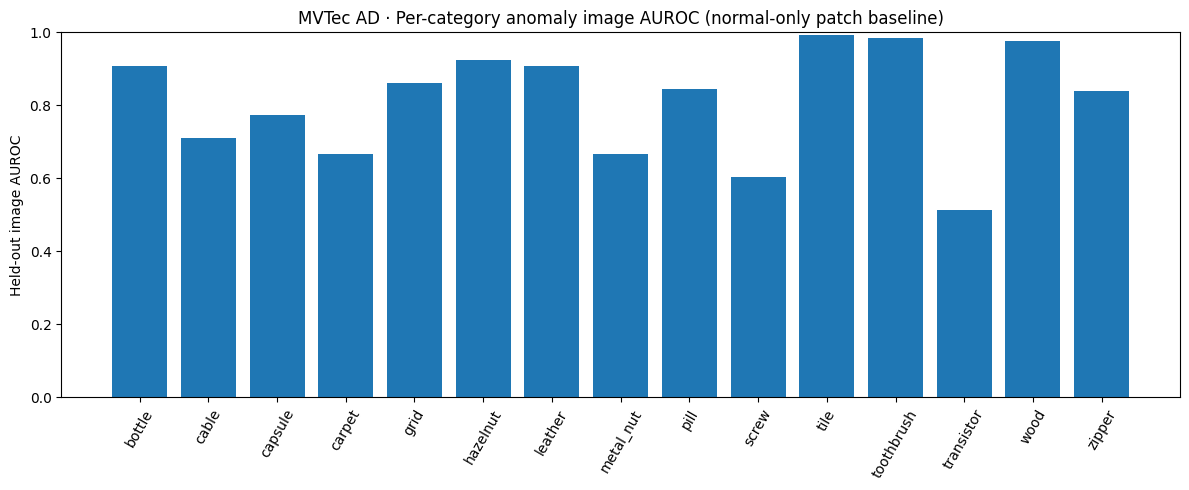

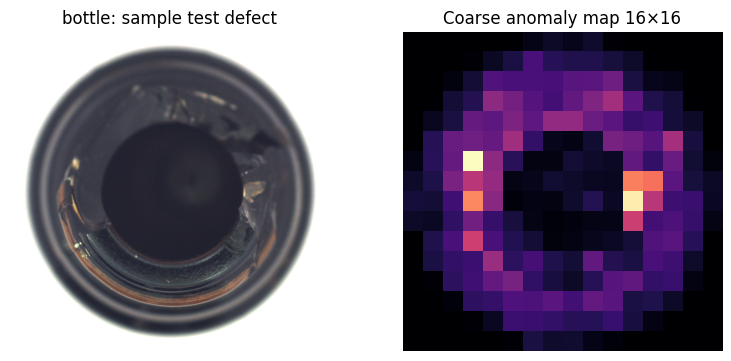

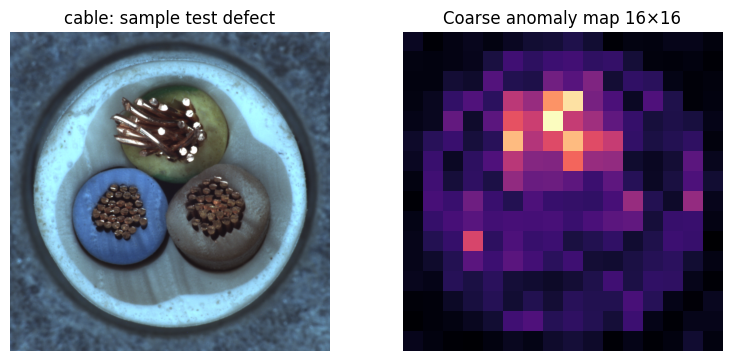

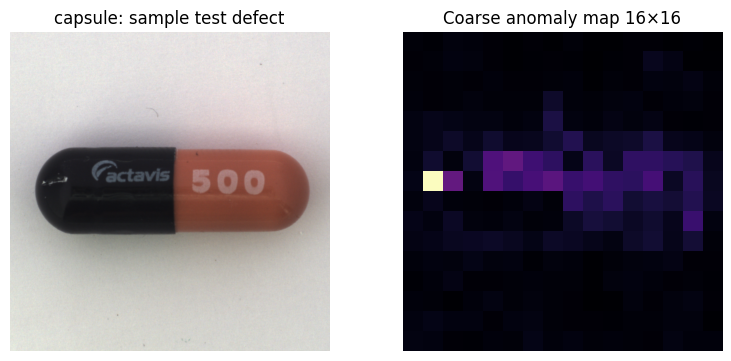

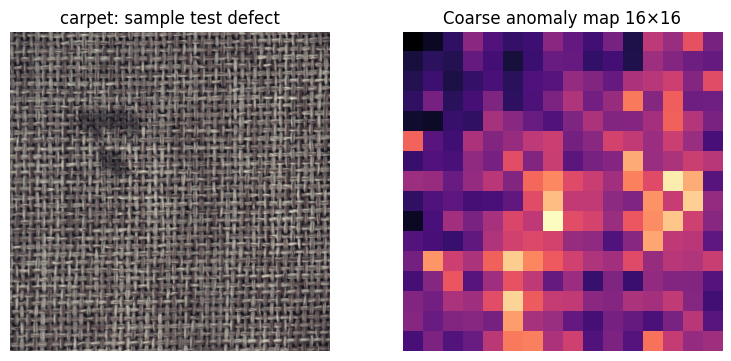

In [6]:
# Plot genuine heldout predictions and examples
fig,ax=plt.subplots(figsize=(12,5))
ax.bar(res_df.category,res_df.image_auroc)
ax.set_ylim(0,1);ax.set_ylabel('Held-out image AUROC');ax.tick_params(axis='x',rotation=60)
ax.set_title('MVTec AD · Per-category anomaly image AUROC (normal-only patch baseline)')
fig.tight_layout();fig.savefig(PLOTS/'mvtec_image_auroc.png',dpi=150);plt.show()
for cat,img,heat in visual_examples[:4]:
 fig,axes=plt.subplots(1,2,figsize=(8,3.7))
 axes[0].imshow(img);axes[0].set_title(f'{cat}: sample test defect');axes[0].axis('off')
 axes[1].imshow(heat,cmap='magma');axes[1].set_title('Coarse anomaly map 16×16');axes[1].axis('off')
 fig.tight_layout();fig.savefig(PLOTS/f'mvtec_example_{cat}.png',dpi=120);plt.show()

## 04 · NEU-DET: parse bounding-box annotations and audit ontology

Each image is matched to its **Pascal VOC XML** by filename stem. The parser reads every labeled object, checks `xmin/ymin/xmax/ymax`, clamps boundary overshoots, and excludes invalid or unreadable items with an audit count.

**Preserve source semantics:** use the actual six observed defect classes from XML. Never derive labels solely from image names or silently collapse classes.

**Evidence:** `reports/neu_annotation_audit.json` includes class box counts, rejected entries, and example filenames. Content hashes are used for downstream duplicate grouping.

**Risk note:** a box may be syntactically valid but visually incorrect; this audit does not replace manual label-quality review.

In [7]:
import xml.etree.ElementTree as ET

# Stem pairing (NEU most commonly uses flat IMAGES/ANNOTATIONS directories).
xml_by_stem=defaultdict(list)
for p in neu_xml:xml_by_stem[p.stem.lower()].append(p)
rows=[];neu_issues=Counter();class_counts=Counter();class_samples=defaultdict(list)
for imgpath in tqdm(neu_images,desc='Audit NEU images/XML'):
 cand=xml_by_stem.get(imgpath.stem.lower(),[])
 if len(cand)!=1:
  neu_issues['missing_or_ambiguous_xml']+=1;continue
 xml=cand[0]
 try:
  root=ET.parse(xml).getroot()
  with Image.open(imgpath) as im: W,H=im.size;im.verify()
  if W<2 or H<2:raise ValueError('Invalid image dimensions')
  boxes=[]
  for obj in root.findall('.//object'):
   name=(obj.findtext('name') or '').strip()
   box=obj.find('bndbox')
   if not name or box is None:neu_issues['malformed_object']+=1;continue
   x1=float(box.findtext('xmin'));y1=float(box.findtext('ymin'));x2=float(box.findtext('xmax'));y2=float(box.findtext('ymax'))
   # Clamp tiny boundary overflows; require positive area.
   if not all(np.isfinite([x1,y1,x2,y2])):neu_issues['nonfinite_box']+=1;continue
   x1=max(0,min(W,float(x1)));x2=max(0,min(W,float(x2)))
   y1=max(0,min(H,float(y1)));y2=max(0,min(H,float(y2)))
   if x2<=x1 or y2<=y1:neu_issues['invalid_box']+=1;continue
   boxes.append((name,(x1,y1,x2,y2)))
   class_counts[name]+=1
   if len(class_samples[name])<3:class_samples[name].append(imgpath.name)
  if not boxes:neu_issues['image_without_valid_boxes']+=1;continue
  rows.append({'image':imgpath,'xml':xml,'width':W,'height':H,'boxes':boxes,'class_set':sorted(set(b[0] for b in boxes))})
 except Exception as e:
  neu_issues['parse_or_image_error']+=1
  if neu_issues['parse_or_image_error']<4:print('ERROR',imgpath,e)
print('Eligible images:',len(rows),'issues:',dict(neu_issues),'source classes:',dict(class_counts))
assert rows,'No valid NEU XML/image pairs found'
classes=sorted(class_counts)
print('Detected classes:',classes,'count',len(classes))
(REPORT/'neu_annotation_audit.json').write_text(json.dumps({'valid_images':len(rows),'classes':classes,'class_box_counts':dict(class_counts),'issues':dict(neu_issues),'examples':dict(class_samples)},indent=2))
# Exact hash family grouping to avoid same image content in multiple splits
for r in tqdm(rows,desc='Hashing NEU images'):
 r['sha256']=file_sha256(r['image'])
 # Common augmented image variants suffix; this does not guarantee all near-duplicates removed
 import re
 r['family']=re.sub(r'(_jpg)?[._]rf[._][0-9a-f]+$', '',r['image'].stem.lower())
print('Images',len(rows),'unique SHA256',len({r['sha256'] for r in rows}),'families',len({r['family'] for r in rows}))

Audit NEU images/XML:   0%|          | 0/1800 [00:00<?, ?it/s]

Eligible images: 1800 issues: {} source classes: {'crazing': 689, 'patches': 881, 'inclusion': 1011, 'pitted_surface': 432, 'rolled-in_scale': 628, 'scratches': 548}
Detected classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches'] count 6


Hashing NEU images:   0%|          | 0/1800 [00:00<?, ?it/s]

Images 1800 unique SHA256 1799 families 1800


## 05 · Leakage-aware 70 / 15 / 15 NEU split

The procedure unifies **filename families** and **exact file hash duplicates** into non-overlapping groups, retains one copy of each exact duplicate, and searches deterministic seeds for a grouped 70/15/15 train/validation/test allocation where **all original classes** occur in each partition.

| Split | Use | Policy |
|---|---|---|
| Train ≈70% | Fit YOLOv8n | Training only |
| Validation ≈15% | Model selection / early stopping | May influence checkpoint selection |
| Test ≈15% | Final held-out audit | Evaluate only after selection |

**Critical boundary:** selecting a split with class coverage uses annotation frequencies, not predictions; proportions are approximate because groups vary in size. An original upstream official test split, if present, should be respected in future work. Exact hashes and filename-family grouping **do not guarantee** elimination of visual near-duplicates.

**Output:** `reports/neu_split_audit.json`, including selection attempt and duplicate counts. An impossible class-complete grouping fails with a diagnostic rather than silently dropping a class.

In [8]:
from sklearn.model_selection import GroupShuffleSplit
# Union-find across filename family and exact image hashes
parent=list(range(len(rows)))
def find(i):
 while parent[i]!=i:
  parent[i]=parent[parent[i]];i=parent[i]
 return i
def union(a,b): parent[find(a)]=find(b)
owner_family={};owner_hash={}
for i,r in enumerate(rows):
 for d,key in ((owner_family,r['family']),(owner_hash,r['sha256'])):
  if key in d:union(i,d[key])
  else:d[key]=i
for i,r in enumerate(rows):r['group']=str(find(i))
# Exclude exact duplicates from same group, retaining one; families with distinct images are all retained
unique=[];seen_hash=set()
for r in rows:
 if r['sha256'] in seen_hash:continue
 seen_hash.add(r['sha256']);unique.append(r)
all_classes=set(classes)
# Deterministic candidate search: group integrity is mandatory; class coverage is mandatory.
# Retry seeds without modifying the 70/15/15 target or leaking test labels into training.
# Split selection inspects source class annotations solely for feasibility of coverage.
all_classes=set(classes)
def split_classes(rr):
 return set(label for r in rr for label,_ in r['boxes'])
chosen=None
for attempt in range(250):
 group_ids=[r['group'] for r in unique]
 splitter=GroupShuffleSplit(n_splits=1,test_size=.15,random_state=SEED+attempt)
 ix_trainval,ix_test=next(splitter.split(unique,groups=group_ids))
 candidate_trainval=[unique[i] for i in ix_trainval]
 candidate_test=[unique[i] for i in ix_test]
 ix_train,ix_val=next(GroupShuffleSplit(n_splits=1,test_size=.17647,random_state=SEED+1000+attempt).split(candidate_trainval,groups=[r['group'] for r in candidate_trainval]))
 candidate_train=[candidate_trainval[i] for i in ix_train]
 candidate_val=[candidate_trainval[i] for i in ix_val]
 if all(part and split_classes(part)==all_classes for part in (candidate_train,candidate_val,candidate_test)):
  chosen=(candidate_train,candidate_val,candidate_test,attempt)
  break
if chosen is None:
 raise RuntimeError('No class-complete leakage-safe grouped NEU 70/15/15 split found in 250 deterministic attempts. Inspect annotation_audit: very rare classes/groups may prevent coverage. Do not silently omit them.')
train_rows,val_rows,test_rows,split_attempt=chosen
by_split={'train':train_rows,'val':val_rows,'test':test_rows}
for sp,rr in by_split.items():
 print(sp,'images',len(rr),'box labels',dict(Counter(b[0] for r in rr for b in r['boxes'])))
train_groups=set(r['group'] for r in train_rows)
val_groups=set(r['group'] for r in val_rows)
test_groups=set(r['group'] for r in test_rows)
assert not(train_groups&val_groups or train_groups&test_groups or val_groups&test_groups),'Leakage detected'
missing_train=all_classes-split_classes(train_rows)
missing_val=all_classes-split_classes(val_rows)
missing_test=all_classes-split_classes(test_rows)
print('Split search attempt:',split_attempt,'Missing classes:',missing_train,missing_val,missing_test)
(REPORT/'neu_split_audit.json').write_text(json.dumps({'split_sizes':{k:len(v) for k,v in by_split.items()},'classes':classes,'missing_class_in_train':sorted(missing_train),'missing_class_in_val':sorted(missing_val),'missing_class_in_test':sorted(missing_test),'exact_image_duplicates_excluded':len(rows)-len(unique),'family_groups':len(set(r['group'] for r in unique)),'split_method':'seeded grouped split with deterministic class-coverage search; exact-hash and filename-family union','selection_attempt':split_attempt},indent=2))

train images 1259 box labels {'crazing': 475, 'patches': 639, 'inclusion': 729, 'pitted_surface': 294, 'rolled-in_scale': 441, 'scratches': 373}
val images 270 box labels {'crazing': 115, 'inclusion': 157, 'patches': 126, 'pitted_surface': 73, 'rolled-in_scale': 73, 'scratches': 95}
test images 270 box labels {'crazing': 99, 'patches': 113, 'inclusion': 125, 'pitted_surface': 65, 'rolled-in_scale': 114, 'scratches': 80}
Split search attempt: 0 Missing classes: set() set() set()


510

### XML → YOLO conversion

The next cell copies eligible images into an isolated staged dataset, normalizes box centers/width/height to `[0,1]`, and writes one label text file per image. A manifest records original paths, checksums, groups, and box counts to support debugging and provenance.

In [9]:
# Stage all eligible unique NEU images, writing YOLO labels from XML
import yaml
for split,rr in by_split.items():
 for sub in ('images','labels'):(STAGED/split/sub).mkdir(parents=True,exist_ok=True)
 manifest=[]
 for idx,r in enumerate(tqdm(rr,desc='Staging NEU '+split)):
  source=r['image'];stem=f'neu_{idx:05d}_{r["sha256"][:12]}'
  dest=STAGED/split/'images'/(stem+source.suffix.lower())
  shutil.copy2(source,dest)
  txt=[]
  for label,(x1,y1,x2,y2) in r['boxes']:
   W,H=r['width'],r['height']
   xc=(x1+x2)/2/W;yc=(y1+y2)/2/H;w=(x2-x1)/W;h=(y2-y1)/H
   txt.append(f'{classes.index(label)} {xc:.8f} {yc:.8f} {w:.8f} {h:.8f}')
  (STAGED/split/'labels'/(stem+'.txt')).write_text('\n'.join(txt)+'\n')
  manifest.append({'split':split,'source':str(source),'image':str(dest.relative_to(STAGED)),'sha256':r['sha256'],'group':r['group'],'boxes':len(txt)})
 pd.DataFrame(manifest).to_csv(REPORT/f'neu_{split}_manifest.csv',index=False)
config={'path':str(STAGED),'train':'train/images','val':'val/images','test':'test/images','names':{i:c for i,c in enumerate(classes)}}
(STAGED/'data.yaml').write_text(yaml.safe_dump(config,sort_keys=False))
print((STAGED/'data.yaml').read_text())

Staging NEU train:   0%|          | 0/1259 [00:00<?, ?it/s]

Staging NEU val:   0%|          | 0/270 [00:00<?, ?it/s]

Staging NEU test:   0%|          | 0/270 [00:00<?, ?it/s]

path: /kaggle/working/defectspot_day22/neu_yolo
train: train/images
val: val/images
test: test/images
names:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches



## 06 · NEU-DET object detection — YOLOv8n

**Architecture:** pretrained `yolov8n.pt` fine-tuned on parsed XML box labels converted to YOLO format. The notebook retains **70 maximum epochs**, `patience=20`, `imgsz=640`, `batch=16` and `seed=42`. The final checkpoint is selected through validation, **not** test metrics.

**Run guidance:** Enable Kaggle GPU for practical training speed. Internet/network access may be necessary to obtain pretrained YOLO weights on the first run. Check runtime package compatibility before rerunning a partially completed session.

**Artifacts:** training curves and `models/neu_best.pt` copied from the actual returned Ultralytics run directory. A successful call does not itself guarantee good mAP: read the final held-out test cell.

In [10]:
if importlib.util.find_spec('ultralytics') is None:
 subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics>=8.3,<9'])
import ultralytics
from ultralytics import YOLO
print('ultralytics',ultralytics.__version__)
if not CFG['neu_train']:raise RuntimeError('NEU training disabled; enable CFG["neu_train"]')
device=0 if torch.cuda.is_available() else 'cpu'
model=YOLO(CFG['neu_model'])
begin=time.time()
results=model.train(data=str(STAGED/'data.yaml'),epochs=CFG['neu_epochs'],imgsz=CFG['neu_imgsz'],batch=CFG['neu_batch'],patience=CFG['neu_patience'],workers=CFG['neu_workers'],device=device,seed=SEED,project=str(RUNS),name='neu_yolov8n',exist_ok=True,save=True,save_period=10,plots=True,amp=bool(torch.cuda.is_available()),verbose=True)
print('NEU train seconds',round(time.time()-begin,1))
best=Path(results.save_dir)/'weights'/'best.pt'
if not best.exists():raise FileNotFoundError(f'Best checkpoint missing: {best}')
shutil.copy2(best,MODELS/'neu_best.pt')
print('Best checkpoint',MODELS/'neu_best.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.190
Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/defectspot_day22/neu_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.4, exist_ok=True, fliplr=0.5, flip

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/70       2.5G      1.651      2.026      1.684         59        640: 100% ━━━━━━━━━━━━ 79/79 9.4it/s 8.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.4it/s 1.7s
                   all        270        638      0.275      0.376      0.276       0.11

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/70       2.5G      1.647        1.9      1.696         52        640: 100% ━━━━━━━━━━━━ 79/79 9.2it/s 8.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.4it/s 1.7s
                   all        270        638      0.623      0.366      0.384      0.168

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/70       2.5G      1.641      1.907      1.704         45        640: 100% ━━━━━━━━━━━━ 79/79 8.9it/s 8.9s
                 Class     Images  Instances      Box(P          R

### Final held-out NEU-DET evaluation

Precision, recall, mAP@0.5 and mAP@0.5:0.95 below are computed on the **test split**, never used to select the checkpoint. Ultralytics-generated plots are copied to the report folder if present. Preview predictions are qualitative examples and cannot replace aggregate metrics.

In [11]:
# NEU final test — train and val may select model, test never used for model selection
best_model=YOLO(str(MODELS/'neu_best.pt'))
test_result=best_model.val(data=str(STAGED/'data.yaml'),split='test',imgsz=CFG['neu_imgsz'],batch=CFG['neu_batch'],device=device,project=str(RUNS),name='neu_final_heldout_test',exist_ok=True,plots=True,verbose=True)
metrics={'model':CFG['neu_model'],'classes':classes,'test_images':len(test_rows),'precision':float(test_result.box.mp),'recall':float(test_result.box.mr),'map50':float(test_result.box.map50),'map50_95':float(test_result.box.map),'per_class_ap50_95':{classes[i]:float(v) for i,v in enumerate(test_result.box.maps)}}
(REPORT/'neu_heldout_metrics.json').write_text(json.dumps(metrics,indent=2))
print(json.dumps(metrics,indent=2))
# Copy genuine training and test visualizations for external report
for sub,prefix in [(Path(results.save_dir),'train'),(Path(test_result.save_dir),'test')]:
 for filename in ('results.png','confusion_matrix.png','PR_curve.png','F1_curve.png'):
  src=sub/filename
  if src.exists():shutil.copy2(src,PLOTS/f'neu_{prefix}_{filename}')
sample=[str(p) for p in sorted((STAGED/'test'/'images').iterdir())[:12]]
if sample:best_model.predict(sample,conf=.25,save=True,device=device,project=str(RUNS),name='neu_test_previews',exist_ok=True,verbose=False)

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 479.8±214.1 MB/s, size: 15.6 KB)
val: Scanning /kaggle/working/defectspot_day22/neu_yolo/test/labels... 270 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 270/270 1.2Kit/s 0.2s
val: New cache created: /kaggle/working/defectspot_day22/neu_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 5.1it/s 3.3s
                   all        270        596      0.719      0.737      0.785       0.46
               crazing         45         99      0.516      0.343      0.439      0.173
             inclusion         49        125      0.724      0.841       0.86      0.462
               patches         51        113      0.837      0.912      0.946      0.615
        pitted_surface         48    

## 07 · Artifacts, inference, and release packaging

Both experiments remain independent:

- **MVTec** saves a separate normal-reference `.joblib` per category and reports its coarse anomaly map.
- **NEU-DET** saves the selected YOLO checkpoint (`.pt`) and optionally exports ONNX. ONNX failures are recorded as optional-export failures; they do not invalidate the `.pt` checkpoint.

The final ZIP contains **models + reports + plots + dataset YAML**, not raw data copies. File size may be large because multiple patch-reference banks are intentionally retained.

**Before deployment:** verify dataset rights, untrusted artifact handling, source-version pinning, inference latency, camera/domain shift, and manual quality control.

In [12]:
if CFG['make_onnx']:
 try:
  path=Path(str(best_model.export(format='onnx',imgsz=CFG['neu_imgsz'],simplify=False,opset=12)))
  if path.exists():shutil.copy2(path,MODELS/'neu_best.onnx')
  print('ONNX:',path)
 except Exception as ex:print('ONNX optional export failed:',repr(ex))
# Example inference from saved NEU and MVTec models
print('NEU model classes:',best_model.names)
for cat in mvtec_categories[:2]:
 p=images_below(cat/'test')
 if p:
  payload=joblib.load(MODELS/f'mvtec_patch_{cat.name}.joblib')
  img=open_rgb(p[0]); s,m=score_image(img,(payload['nn'],payload['mu'],payload['sigma']))
  print('MVTec inference example',cat.name,p[0].name,'raw anomaly score',round(s,4))

Ultralytics 8.4.190 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/defectspot_day22/models/neu_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (6.2 MB)

ONNX: starting export with onnx 1.22.0 opset 12...
ONNX: export success ✅ 1.0s, saved as '/kaggle/working/defectspot_day22/models/neu_best.onnx' (12.2 MB)

Export complete (1.2s)
Results saved to /kaggle/working/defectspot_day22/models/neu_best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/defectspot_day22/models/neu_best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/defectspot_day22/models/neu_best.onnx imgsz=640 data=/kaggle/working/defectspot_day22/neu_yolo/data.yaml 
Vi

### Reproducible release manifest

The final cell writes one `final_summary.json` with **separate** MVTec and NEU results, study limitations and both input roots. An export ZIP aggregates *computed* reports, trained models, and plots. Failed upstream cells should prevent release rather than generating partially fabricated successes.

In [13]:
# One auditable summary; metrics remain separate
final={'project':'DefectSpot','day':22,'mvtec':summary_mvtec,'neu':metrics,'input_roots':{'mvtec':str(ROOT_M),'neu':str(ROOT_N)},'limitations':[
 'NEU-DET object detection and MVTec anomaly detection are distinct tasks; scores are not directly comparable.',
 'MVTec training contains normal images only; no defect masks or test labels are used to fit normal patch bank.',
 'MVTec patch map resolution is 16x16, not high-resolution segmentation; scores are uncalibrated.',
 'NEU split is grouped by filename-family and exact file hash, but near-duplicate scenes may remain.',
 'NEU defect classes do not establish other manufacturing defect types outside the dataset.',
 'MVTec dataset licensing is non-commercial CC BY-NC-SA 4.0; review NEU license and downstream use.'
 ]}
(REPORT/'final_summary.json').write_text(json.dumps(final,indent=2))
print(json.dumps(final,indent=2))
from zipfile import ZipFile,ZIP_DEFLATED
bundle=Path('/kaggle/working/DefectSpot_Day22_Models_Reports.zip')
with ZipFile(bundle,'w',ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
 for root,arc in [(REPORT,'reports'),(MODELS,'models'),(PLOTS,'plots')]:
  for p in sorted(root.rglob('*')):
   if p.is_file():z.write(p,arcname=f'{arc}/{p.relative_to(root).as_posix()}')
 z.write(STAGED/'data.yaml',arcname='neu_dataset_config.yaml')
print('Saved bundle:',bundle,'MiB:',round(bundle.stat().st_size/(1024**2),2))

{
  "project": "DefectSpot",
  "day": 22,
  "mvtec": {
    "categories_evaluated": 15,
    "total_test_images": 1725,
    "macro_image_auroc": 0.8117201369814974,
    "macro_coarse_pixel_auroc": 0.8882390812385788,
    "method": "handcrafted normal-only patch-bank NN",
    "caution": "Image AP prevalence-dependent; coarse pixel AUROC is on 16x16 patch grid; not official MVTec benchmark protocol"
  },
  "neu": {
    "model": "yolov8n.pt",
    "classes": [
      "crazing",
      "inclusion",
      "patches",
      "pitted_surface",
      "rolled-in_scale",
      "scratches"
    ],
    "test_images": 270,
    "precision": 0.7189064143010121,
    "recall": 0.7365388728769836,
    "map50": 0.7851796208675718,
    "map50_95": 0.4603302844100538,
    "per_class_ap50_95": {
      "crazing": 0.17294711560846449,
      "inclusion": 0.46156591315323503,
      "patches": 0.6152720096321208,
      "pitted_surface": 0.6121977720142702,
      "rolled-in_scale": 0.33013143375777004,
      "scratches":

## 08 · Limitations, reproducibility and claim boundaries

### Valid conclusions
- **MVTec:** per-category *held-out* image AUROC/AP and coarse patch-map AUROC computed from the source test partition; not high-resolution segmentation accuracy.
- **NEU-DET:** object-level precision, recall, mAP@0.5, and mAP@0.5–0.95 on a leakage-aware group test partition.
- Different datasets, target labels, algorithms, and metrics mean the two experiments **must never be ranked against each other**.

### What this notebook does *not* establish
- Factory-grade safety or real-time inspection speed.
- Calibrated probability of a faulty product, causal defect diagnosis, or cross-factory generalization.
- Official MVTec benchmark equivalence, PatchCore reproduction, or complete exclusion of near-duplicate NEU textures.
- Commercial use permission for MVTec (licensed CC BY-NC-SA 4.0); NEU license terms require separate verification.

### Final run checklist
1. Add **both Kaggle datasets** and verify the discovered input directories.
2. Select GPU if available; install/verify `ultralytics` and pretrained checkpoint access.
3. **Run all cells sequentially**, inspect audit warnings and actual held-out metrics.
4. Confirm `reports/final_summary.json`, `models/neu_best.pt`, MVTec category banks and the final ZIP exist.
5. Use **Save Version → Save & Run All** in Kaggle; only publish metrics returned by the completed run.

**Next research milestones:** domain-aware near-duplicate audit, stronger learned-feature anomaly baseline, external production-image validation, latency benchmarking, model cards and permission-aware distribution.